        # Cognitive Science (1204 427) — Lab 12
        ## Signal Detection Theory and Decision Making

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy, scikit-learn`

        ### แนวคิดสำคัญ

        Signal Detection Theory แยก Sensitivity ($d'$) ออกจาก Response Bias ($c$) ทำให้เห็นว่าความแม่นยำเพียงค่าเดียวอาจปิดบังกลยุทธ์การตัดสินใจ

        ### วัตถุประสงค์

        คำนวณ Confusion Outcomes, SDT Metrics, ROC/AUC และเลือก Threshold ภายใต้ต้นทุนความผิดพลาดที่ต่างกัน

        ### งานที่ต้องทำ

        1. สร้าง Signal/Noise Evidence
2. คำนวณ Hit, Miss, False Alarm และ Correct Rejection
3. คำนวณ d-prime และ Criterion
4. สร้าง ROC และหา Threshold ด้วย Youden's J
5. Required Extension: เลือก Cost-sensitive Threshold

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(seed + 120)
n = 1000; truth = rng.integers(0, 2, n)
evidence = np.where(truth == 1, rng.normal(1.35, 1.0, n), rng.normal(0.0, 1.0, n))
sdt_df = pd.DataFrame({"truth": truth, "evidence": evidence})

def sdt_metrics(y, x, threshold):
    response = (x >= threshold).astype(int)
    hit = np.sum((y == 1) & (response == 1)); miss = np.sum((y == 1) & (response == 0))
    fa = np.sum((y == 0) & (response == 1)); cr = np.sum((y == 0) & (response == 0))
    hr = (hit + 0.5) / (hit + miss + 1); far = (fa + 0.5) / (fa + cr + 1)
    z_h, z_f = norm.ppf(hr), norm.ppf(far)
    return {"threshold": threshold, "hit": hit, "miss": miss, "false_alarm": fa, "correct_rejection": cr,
            "hit_rate": hr, "false_alarm_rate": far, "d_prime": z_h - z_f, "criterion": -0.5 * (z_h + z_f)}


,value
threshold,0.7041
hit,378.0000
miss,109.0000
false_alarm,108.0000
correct_rejection,405.0000
hit_rate,0.7756
false_alarm_rate,0.2111
d_prime,1.5601
criterion,0.0226
youden_j,0.5645


AUC=0.8557


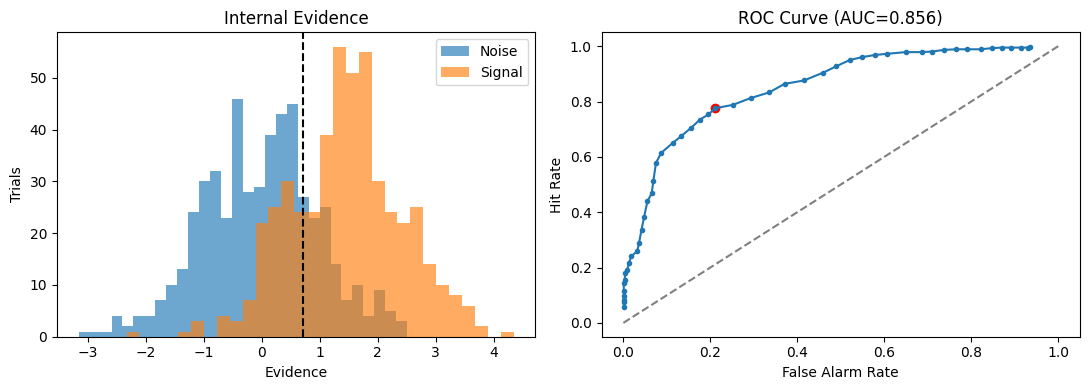

In [3]:
thresholds = np.linspace(-1.5, 3.0, 50)
results = pd.DataFrame([sdt_metrics(truth, evidence, t) for t in thresholds])
results["youden_j"] = results.hit_rate - results.false_alarm_rate
best = results.loc[results.youden_j.idxmax()]
auc = roc_auc_score(truth, evidence)
display(best.round(4).to_frame("value")); print(f"AUC={auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(evidence[truth == 0], bins=30, alpha=.65, label="Noise")
axes[0].hist(evidence[truth == 1], bins=30, alpha=.65, label="Signal")
axes[0].axvline(best.threshold, color="black", linestyle="--"); axes[0].set_xlabel("Evidence"); axes[0].set_ylabel("Trials")
axes[0].set_title("Internal Evidence"); axes[0].legend()
axes[1].plot(results.false_alarm_rate, results.hit_rate, marker="o", markersize=3)
axes[1].plot([0, 1], [0, 1], "--", color="gray"); axes[1].scatter(best.false_alarm_rate, best.hit_rate, color="red")
axes[1].set_xlabel("False Alarm Rate"); axes[1].set_ylabel("Hit Rate"); axes[1].set_title(f"ROC Curve (AUC={auc:.3f})")
plt.tight_layout(); plt.show()


## Required Extension

สมมติว่า Cost ของ Miss = 5 และ Cost ของ False Alarm = 1 คำนวณ Total Cost ของทุก Threshold แล้วเลือก Threshold ที่มีต้นทุนต่ำที่สุด เปรียบเทียบกับ Youden's J


Youden threshold      = 0.704 (miss=109, FA=108, cost=653)
Cost-optimal threshold = -0.214 (miss=15, FA=297, cost=372)


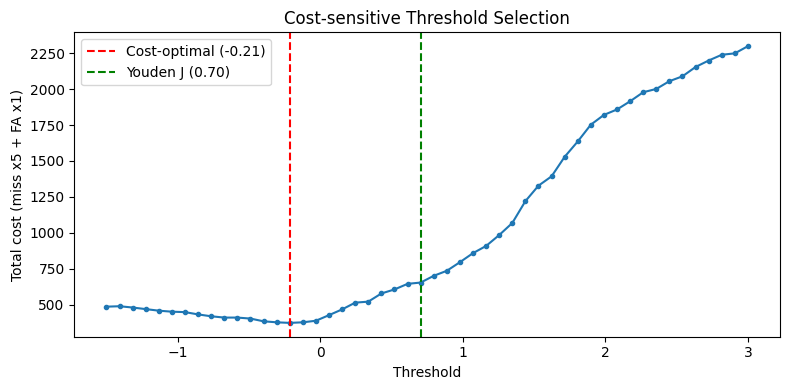

In [4]:
# ===== Required Extension: Cost-sensitive Threshold =====
COST_MISS = 5
COST_FA = 1
results["total_cost"] = COST_MISS * results["miss"] + COST_FA * results["false_alarm"]
cost_best = results.loc[results["total_cost"].idxmin()]

youden_cost = COST_MISS * best["miss"] + COST_FA * best["false_alarm"]
print(f"Youden threshold      = {best.threshold:.3f} (miss={int(best['miss'])}, FA={int(best['false_alarm'])}, cost={int(youden_cost)})")
print(f"Cost-optimal threshold = {cost_best.threshold:.3f} (miss={int(cost_best['miss'])}, FA={int(cost_best['false_alarm'])}, cost={int(cost_best['total_cost'])})")

plt.figure(figsize=(8, 4))
plt.plot(results["threshold"], results["total_cost"], marker="o", markersize=3)
plt.axvline(cost_best.threshold, color="red", linestyle="--", label=f"Cost-optimal ({cost_best.threshold:.2f})")
plt.axvline(best.threshold, color="green", linestyle="--", label=f"Youden J ({best.threshold:.2f})")
plt.xlabel("Threshold")
plt.ylabel(f"Total cost (miss x{COST_MISS} + FA x{COST_FA})")
plt.title("Cost-sensitive Threshold Selection")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 12

**1. d-prime และ Criterion ต่างกันอย่างไร**

d-prime (~1.56) วัด sensitivity คือระยะห่างระหว่างการแจกแจง signal กับ noise (แยกเก่งแค่ไหน) ไม่ขึ้นกับกลยุทธ์ตอบ ส่วน criterion (~0.02) วัด response bias คือแนวโน้มเอนไปตอบ "ใช่/ไม่ใช่" ที่จุด Youden ค่านี้ ≈ 0 แปลว่าเกณฑ์ค่อนข้างเป็นกลาง

**2. Threshold เปลี่ยน Sensitivity หรือ Response Bias**

เปลี่ยนแค่ response bias (criterion) ครับ ไม่เปลี่ยน sensitivity ที่แท้จริง เพราะระยะห่าง signal/noise ถูกกำหนดจากข้อมูลแล้ว หลักฐานคือ AUC (~0.856) เป็นค่าเดียวทั้งชุด ไม่ว่าจะเลื่อน threshold ไปไหน จุดก็แค่วิ่งไปตาม ROC เส้นเดิม

**3. AUC บอกข้อมูลอะไรเหนือ Accuracy ณ Threshold เดียว**

AUC สรุป performance ข้ามทุก threshold (threshold-free) แทนความน่าจะเป็นที่ระบบให้คะแนน signal สูงกว่า noise ส่วน accuracy ที่ threshold เดียวขึ้นกับ bias และสัดส่วน signal/noise เลยบิดง่าย AUC จึงเทียบความสามารถของระบบได้ยุติธรรมกว่า

**4. Cost-sensitive Threshold ต่างจาก Youden Threshold อย่างไร**

Youden เลือกจุดที่ hit rate - FA rate สูงสุด (ถือว่า error สองแบบสำคัญเท่ากัน) ส่วน cost-sensitive ถ่วงน้ำหนักตามต้นทุน จากผลนี้พอให้ miss แพงกว่า (×5) threshold เลื่อนลงเหลือ ~-0.21 (จาก 0.70) ทำให้ miss ลดจากเยอะเหลือ ~15 แลกกับ FA ที่มากขึ้น รวมแล้ว total cost ต่ำกว่าจุด Youden ชัดเจน

**5. ถ้าใช้คัดกรองโรคร้ายแรงควรให้น้ำหนัก Error ประเภทใดมากกว่า เพราะเหตุใด**

ควรให้ Miss (False Negative) แพงกว่ามาก เพราะบอกว่าไม่ป่วยทั้งที่ป่วยจริงอันตรายกว่า (ผู้ป่วยไม่ได้รักษาทัน) ส่วน False Alarm ส่งไปตรวจยืนยันเพิ่มได้ ต้นทุนต่ำกว่า จึงควรตั้ง threshold ต่ำเพื่อเพิ่ม sensitivity ยอมรับ FA มากขึ้นเพื่อไม่พลาดผู้ป่วย

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนคิด total cost ตอนแรกงงว่าจะถ่วงน้ำหนัก miss กับ FA ยังไง พอเขียนเป็น 5×miss + 1×FA แล้วหา threshold ที่ต้นทุนต่ำสุด เห็นชัดว่ามันเลื่อนไปคนละที่กับ Youden เลย ทำให้เข้าใจว่า 'จุดที่ดีที่สุด' ขึ้นกับว่าเรามองต้นทุนยังไง

สิ่งที่เข้าใจมากขึ้นคือ d-prime กับ criterion เป็นคนละเรื่อง และ threshold แค่เลื่อน bias ไม่ได้ทำให้ระบบเก่งขึ้น (AUC คงที่) พอเอามาเชื่อมกับการคัดกรองโรคจริง ก็เห็นว่าการเลือก operating point สำคัญมากในทางปฏิบัติ

ถ้าทำซ้ำ อยากลองต้นทุนหลายอัตราส่วน (เช่น 10:1) เพื่อดูว่า threshold ขยับไปแค่ไหน และลองวาด cost บน ROC เพื่อให้เห็นภาพ trade-off ชัดขึ้น

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
